# 04. 손익분기 · 소득 변화 분해 · 품종별 경영비 물가

`03_cost_inflation`에서 만든 **표준소득표(2016~2024년산)**와 **농가구입가격지수**로 네 가지를 더 봅니다.

| 절 | 질문 |
| --- | --- |
| 1 | 노지온주는 단가가 얼마 아래로 내려가면 적자인가? 제주 생산량이 몇 톤을 넘으면 위험한가? |
| 2 | 품종별 소득이 늘거나 줄어든 것은 가격 때문인가, 수확량 때문인가, 비용 때문인가? |
| 3 | 표준표가 제주 평균보다 높은 것은 수확량 차이인가, 단가 차이인가? |
| 4 | 품종마다 비용 구성이 다를 때, 비용 물가로 보정하면 결론이 어떻게 달라지는가? |

**용어**
- **표준 농가**: 표준소득표의 표본 농가 (10a당 값)
- **제주 평균**: jasdc 생산 통계로 계산한 제주 전체 평균 (`조수입 ÷ 재배면적` 등)
- **소득** = 총수입 − 경영비 (자가노동 보상이 남아 있음), **순수익** = 총수입 − 생산비 (자가노동비·자본용역비까지 차감)

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from jeju_citrus.config import FIGURES_DIR
from jeju_citrus.data import (
    load_cpi,
    load_farm_purchase_index,
    load_processed,
    load_standard_income,
    load_standard_income_items,
)
from jeju_citrus.features import COST_ITEM_GROUPS, cost_price_index, cost_weights
from jeju_citrus.visualization import set_style

set_style()
pd.set_option("display.float_format", "{:,.1f}".format)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
VARIETIES = ["노지온주", "하우스온주", "월동온주", "한라봉", "천혜향", "레드향", "황금향"]
VCOLOR = dict(zip(VARIETIES, PALETTE))
C1, C2, C3 = PALETTE[:3]
MUTED = "#52514e"
ITEMS = [i for g in COST_ITEM_GROUPS.values() for i in g]

prod = load_processed("citrus_production_yearly")
std = load_standard_income()
items = load_standard_income_items()
farm = load_farm_purchase_index()
cpi = load_cpi().set_index("연도")["CPI_2020_100"]

# 품종별 경영비 물가지수 (가중치: 2024년산 표준소득표 경영비 세부 항목)
weights = {v: cost_weights(g[ITEMS].iloc[0].to_dict()) for v, g in items[items["산지연도"] == 2024].groupby("대응품종")}
cost_idx = pd.DataFrame({v: cost_price_index(farm, w) for v, w in weights.items()})

noji = prod[prod["품종"] == "노지온주"].set_index("연도")
noji_std = std[std["대응품종"] == "노지온주"].set_index("산지연도")

## 1. 노지온주 손익분기

### 1.1 표준 농가의 손익분기 단가

- **경영비 손익분기 단가** = 경영비 ÷ 수량: 이보다 싸게 팔면 현금 비용도 못 건짐
- **생산비 손익분기 단가** = 생산비 ÷ 수량: 이보다 싸게 팔면 자기 노동 대가(제조업 평균임금 기준)를 다 못 받음

In [2]:
be = pd.DataFrame({
    "표준 단가": noji_std["단가_원_kg"],
    "생산비 손익분기": noji_std["생산비_원_10a"] / noji_std["수량_kg_10a"],
    "경영비 손익분기": noji_std["경영비_원_10a"] / noji_std["수량_kg_10a"],
    "수량_kg_10a": noji_std["수량_kg_10a"],
})
be["생산비 대비 단가"] = be["표준 단가"] / be["생산비 손익분기"]
be.style.format({"표준 단가": "{:,.0f}", "생산비 손익분기": "{:,.0f}", "경영비 손익분기": "{:,.0f}", "수량_kg_10a": "{:,.0f}", "생산비 대비 단가": "{:.2f}"})

,표준 단가,생산비 손익분기,경영비 손익분기,수량_kg_10a,생산비 대비 단가
산지연도,,,,,
2016,"1,191",885,324,"3,233",1.35
2017,"1,389",986,391,"3,040",1.41
2018,"1,286","1,026",431,"2,807",1.25
2019,919,954,439,"3,424",0.96
2020,"1,215","1,153",493,"2,939",1.05
2021,"1,311","1,212",490,"3,100",1.08
2022,"1,353","1,416",617,"2,485",0.96
2023,"2,024","1,637",744,"2,557",1.24
2024,"2,597","2,229",956,"1,747",1.17


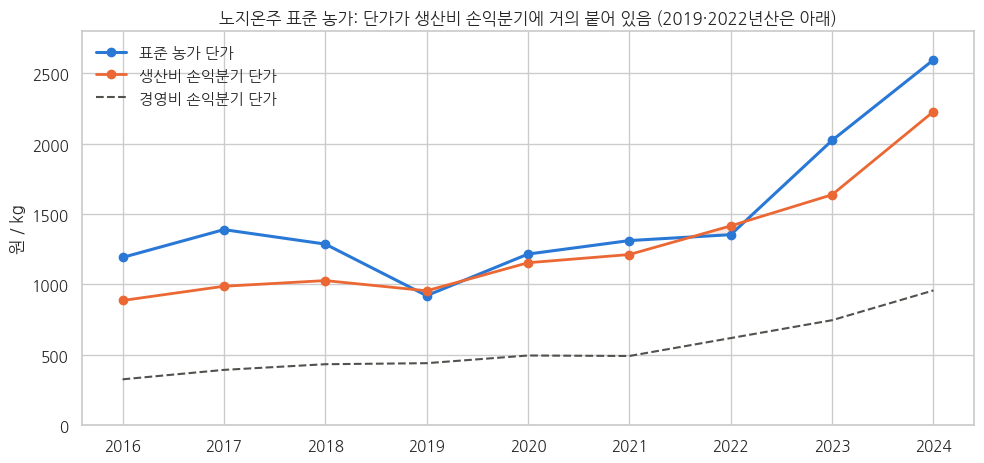

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(be.index, be["표준 단가"], color=C1, linewidth=2.2, marker="o", markersize=6, label="표준 농가 단가")
ax.plot(be.index, be["생산비 손익분기"], color=C2, linewidth=2, marker="o", markersize=6, label="생산비 손익분기 단가")
ax.plot(be.index, be["경영비 손익분기"], color=MUTED, linewidth=1.5, linestyle="--", label="경영비 손익분기 단가")
ax.fill_between(be.index, be["표준 단가"], be["생산비 손익분기"], where=be["표준 단가"] < be["생산비 손익분기"],
                color=C2, alpha=0.15, interpolate=True)
ax.set_ylabel("원 / kg")
ax.set_ylim(0, 2800)
ax.set_title("노지온주 표준 농가: 단가가 생산비 손익분기에 거의 붙어 있음 (2019·2022년산은 아래)")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_noji_breakeven_price.png", dpi=150)
plt.show()

**관찰**

- 경영비 손익분기 단가는 324 → 956원/kg으로 올랐지만, 실제 단가는 9년 내내 그보다 훨씬 높습니다. **현금 비용은 늘 건졌습니다.**
- 반면 **생산비 손익분기 단가와 실제 단가는 거의 붙어 있습니다**(0.96~1.35배). 2019·2022년산은 단가가 손익분기보다 낮아서, 자기 노동 대가를 다 받지 못했습니다.
- 손익분기 단가는 2016년 885원에서 2024년 2,229원으로 2.5배가 됐습니다. 비용이 오른 데다(생산비 +36%) **2024년산 수량이 1,747kg/10a로 크게 줄었기 때문**입니다. 수확이 적은 해는 kg당 비용이 올라갑니다.

### 1.2 제주 평균 농가로 바꾸면

표준 농가는 단가가 제주 평균보다 높고(약 1.2배) 수량은 비슷하거나 적습니다(3절). 제주 평균 매출(`ha당 조수입`)에서 표준 경영비·생산비를 빼서 **평균 농가의 소득·순수익을 추정**했습니다. 비용은 평균 농가도 표준 농가와 같다고 가정합니다.

In [4]:
avg = pd.DataFrame({
    "제주 평균 매출": noji.loc[2016:2024, "ha당_조수입_백만원"] * 10,  # 백만원/ha → 만원/10a
    "경영비": noji_std["경영비_만원_10a"],
    "생산비": noji_std["생산비_만원_10a"],
})
avg["평균 농가 소득"] = avg["제주 평균 매출"] - avg["경영비"]
avg["평균 농가 순수익"] = avg["제주 평균 매출"] - avg["생산비"]
avg["제주 생산량_만톤"] = noji.loc[2016:2024, "생산량_톤"] / 1e4
print("단위: 만원/10a")
avg.round(1)

단위: 만원/10a


,제주 평균 매출,경영비,생산비,평균 농가 소득,평균 농가 순수익,제주 생산량_만톤
2016,295.7,104.6,286.0,191.1,9.7,46.7
2017,357.9,118.8,299.7,239.1,58.2,44.0
2018,337.7,121.0,288.1,216.7,49.6,46.8
2019,272.2,150.2,326.6,122.0,-54.4,49.1
2020,319.9,145.0,339.0,174.9,-19.1,51.6
2021,333.6,151.8,375.6,181.8,-42.0,46.7
2022,339.9,153.4,351.8,186.5,-11.9,42.9
2023,444.7,190.3,418.7,254.4,26.0,40.6
2024,469.4,167.0,389.4,302.4,80.0,37.2


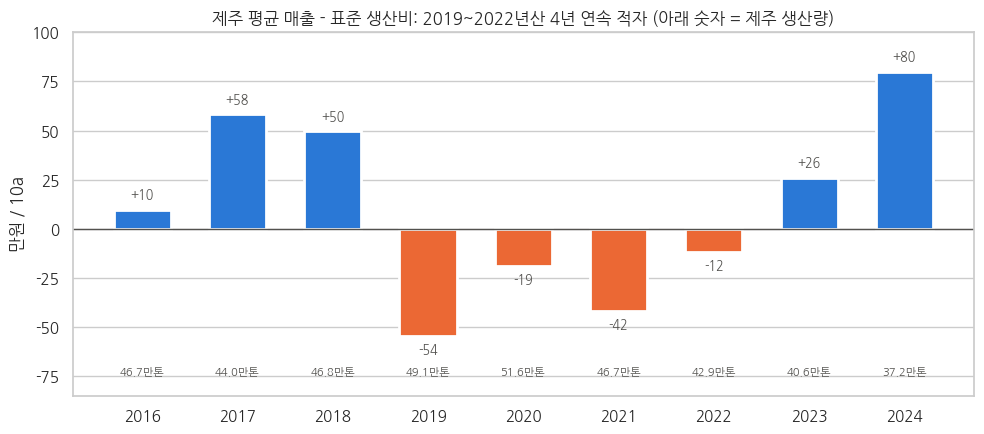

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
vals = avg["평균 농가 순수익"]
ax.bar(vals.index, vals.values, color=[C1 if v >= 0 else C2 for v in vals], width=0.6, edgecolor="white", linewidth=2)
for x, v, q in zip(vals.index, vals.values, avg["제주 생산량_만톤"]):
    ax.text(x, v + (4 if v >= 0 else -4), f"{v:+.0f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, color=MUTED)
    ax.text(x, -75, f"{q:.1f}만톤", ha="center", fontsize=8, color=MUTED)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylim(-85, 100)
ax.set_xticks(vals.index)
ax.set_ylabel("만원 / 10a")
ax.set_title("제주 평균 매출 - 표준 생산비: 2019~2022년산 4년 연속 적자 (아래 숫자 = 제주 생산량)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_noji_avg_net_profit.png", dpi=150)
plt.show()

**관찰**

- 제주 평균 농가는 **경영비를 빼면 9년 내내 흑자**(122~302만원/10a)지만, **생산비를 빼면 2019~2022년산 4년 연속 적자**(−12 ~ −54만원/10a)입니다.
- 적자 4년 중 2019·2020년산은 생산량이 49~52만 톤으로 많았던 해입니다. 2021·2022년산은 생산량이 43~47만 톤으로 많지 않았지만, 2022년에 비료비·광열비가 급등하는 등 비용이 오른 해입니다.
- 흑자로 돌아선 2023·2024년산은 생산량이 37~41만 톤으로 적어서 가격이 크게 오른 해입니다.

### 1.3 제주 생산량이 몇 톤을 넘으면 적자인가?

생산량과 가격의 관계를 추정해서 **"평균 농가가 생산비를 겨우 건지는 생산량"**을 계산합니다.

1. 2015~2025년 노지온주 단가를 **노지 경영비지수로 2025년 비용 수준에 맞춰** 실질화합니다.
2. `log(실질 단가) = a + b·log(생산량) + c·(연도 − 2025)` 를 추정합니다. `02` §5의 모델 B와 같은 형태이고, 기준선('전년 단가 그대로')보다 약간 나은 수준이었습니다.
3. 2026년 추세값에서 생산량별 ha당 매출 = 단가 × 생산량 ÷ 재배면적(2025년 13,972ha)을 계산해서, 2022~2024년 평균 생산비(2025년 비용 수준)와 같아지는 생산량을 찾습니다.

In [6]:
d = noji.loc[2015:2025].copy()
d["실질단가"] = d["단가_원_kg"] / cost_idx["노지온주"] * cost_idx.loc[2025, "노지온주"]
X = np.column_stack([np.ones(len(d)), np.log(d["생산량_톤"]), d.index - 2025])
y = np.log(d["실질단가"].to_numpy())
coef = np.linalg.lstsq(X, y, rcond=None)[0]
resid_sd = (y - X @ coef).std(ddof=X.shape[1])
print(f"생산량 탄력성 b = {coef[1]:.2f},  연 추세 c = {coef[2]:+.3f},  잔차 표준편차 = {resid_sd:.2f} (단가가 모델에서 평균 ±{np.expm1(resid_sd):.0%} 벗어남)")

AREA = noji.loc[2025, "재배면적_ha"]
to_2025 = cost_idx.loc[2025, "노지온주"] / cost_idx.loc[2022:2024, "노지온주"]
cost_ha = {  # 원/ha, 2025년 비용 수준
    "생산비": (noji_std.loc[2022:2024, "생산비_원_10a"] * to_2025).mean() * 10,
    "경영비": (noji_std.loc[2022:2024, "경영비_원_10a"] * to_2025).mean() * 10,
}


def predicted(q_ton, year=2026, shift=0.0):
    price = np.exp(coef[0] + coef[1] * np.log(q_ton) + coef[2] * (year - 2025) + shift)
    return price, price * q_ton * 1000 / AREA  # 원/kg, 원/ha


def threshold(cost, shift=0.0, year=2026):
    # 단가 × 생산량 ÷ 면적 = 비용 을 log로 풀면 생산량이 바로 나온다 (b + 1 < 0 이라 해가 하나)
    ln_q = (np.log(cost) - np.log(1000 / AREA) - coef[0] - coef[2] * (year - 2025) - shift) / (coef[1] + 1)
    return np.exp(ln_q)


thr = pd.DataFrame({k: {"가격 낮은 경우 (−1σ)": threshold(c, -resid_sd), "중앙": threshold(c), "가격 높은 경우 (+1σ)": threshold(c, resid_sd)}
                    for k, c in cost_ha.items()}).T / 1e4
print("손익분기 생산량 (만 톤, 2026년산 기준)")
display(thr.round(1))

scen = pd.DataFrame({"생산량_만톤": [37, 41.1, 45, 47, 50, 55]})
scen["예상 단가_원_kg"], ha = predicted(scen["생산량_만톤"] * 1e4)
scen["ha당 매출_백만원"] = ha / 1e6
scen["순수익_백만원_ha"] = (ha - cost_ha["생산비"]) / 1e6
scen.round(1)

생산량 탄력성 b = -2.05,  연 추세 c = -0.015,  잔차 표준편차 = 0.18 (단가가 모델에서 평균 ±20% 벗어남)
손익분기 생산량 (만 톤, 2026년산 기준)


,가격 낮은 경우 (−1σ),중앙,가격 높은 경우 (+1σ)
생산비,39.4,46.7,55.5
경영비,86.1,102.1,121.3


,생산량_만톤,예상 단가_원_kg,ha당 매출_백만원,순수익_백만원_ha
0,37.0,"1,923.7",50.9,11.1
1,41.1,"1,551.1",45.6,5.7
2,45.0,"1,288.2",41.5,1.6
3,47.0,"1,178.4",39.6,-0.2
4,50.0,"1,038.1",37.1,-2.7
5,55.0,853.9,33.6,-6.3


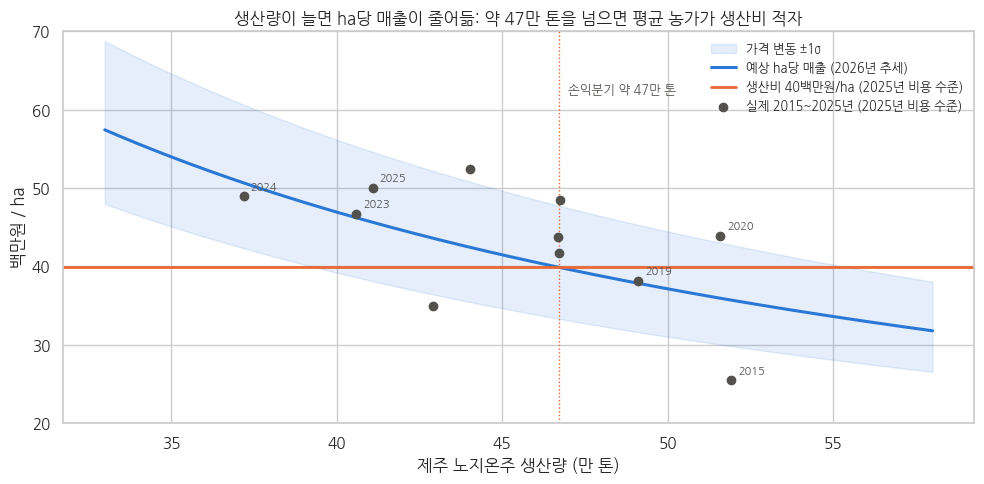

In [7]:
q = np.linspace(33e4, 58e4, 200)
fig, ax = plt.subplots(figsize=(10, 5))
mid = predicted(q)[1] / 1e6
lo, hi = predicted(q, shift=-resid_sd)[1] / 1e6, predicted(q, shift=resid_sd)[1] / 1e6
ax.fill_between(q / 1e4, lo, hi, color=C1, alpha=0.12, label="가격 변동 ±1σ")
ax.plot(q / 1e4, mid, color=C1, linewidth=2.2, label="예상 ha당 매출 (2026년 추세)")
ax.axhline(cost_ha["생산비"] / 1e6, color=C2, linewidth=2, label=f"생산비 {cost_ha['생산비'] / 1e6:.0f}백만원/ha (2025년 비용 수준)")
past = d.assign(실질매출=d["실질단가"] * d["생산량_톤"] * 1000 / d["재배면적_ha"] / 1e6)
ax.scatter(past["생산량_톤"] / 1e4, past["실질매출"], color=MUTED, s=36, zorder=3, label="실제 2015~2025년 (2025년 비용 수준)")
for yr in [2015, 2019, 2020, 2023, 2024, 2025]:
    ax.annotate(yr, (past.loc[yr, "생산량_톤"] / 1e4, past.loc[yr, "실질매출"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8, color=MUTED)
ax.axvline(thr.loc["생산비", "중앙"], color=C2, linewidth=1, linestyle=":")
ax.annotate(f"손익분기 약 {thr.loc['생산비', '중앙']:.0f}만 톤", (thr.loc["생산비", "중앙"], 62), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=MUTED)
ax.set_xlabel("제주 노지온주 생산량 (만 톤)")
ax.set_ylabel("백만원 / ha")
ax.set_ylim(20, 70)
ax.set_title("생산량이 늘면 ha당 매출이 줄어듦: 약 47만 톤을 넘으면 평균 농가가 생산비 적자")
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_noji_breakeven_production.png", dpi=150)
plt.show()

**관찰**

- 생산량 탄력성은 약 **−2.0**입니다(`02`의 −2.2 ~ −2.9와 비슷). 생산량이 늘면 가격이 그보다 더 크게 떨어지므로 **많이 생산할수록 ha당 매출이 줄어듭니다.**
- 2026년산 비용 수준에서 **제주 노지온주 생산량이 약 47만 톤을 넘으면 평균 농가가 생산비 기준 적자**가 됩니다. 다만 같은 생산량에서도 가격이 해마다 ±20% 정도 흔들리기 때문에, 실제 경계는 **약 39~56만 톤** 사이에 있습니다.
- 경영비(현금 비용) 기준 손익분기 생산량은 약 100만 톤으로, 2015~2025년 생산량(37~52만 톤)보다 훨씬 많습니다. **위험은 현금 적자가 아니라 자기 노동 대가를 못 받는 쪽입니다.**
- 연 추세 c는 약 −1.5%입니다. 같은 생산량이라도 비용 대비 가격이 매년 조금씩 나빠진다는 뜻입니다. 그래서 손익분기 생산량도 해마다 조금씩 줄어듭니다.

### 1.4 2026년산에 대입하면

- 2025년산 생산량은 41.1만 톤이었습니다. 2026년산 생산량 추정치는 이 프로젝트 데이터에 아직 없습니다.
- `02` §5의 시즌 초반 실측(9/1~11/8)은 **출하량 +33%, 도매가 −7%** 였습니다. 출하가 앞당겨졌을 수도 있으므로, 출하량 증가율을 그대로 생산량 증가율로 볼 수는 없습니다.
- 위 시나리오 표로 보면, 2026년산 생산량이 **45만 톤(+10%)이면 순수익 약 +2백만원/ha, 50만 톤(+22%)이면 약 −3백만원/ha** 로 손익분기 근처입니다.
- **농업관측센터의 2026년산 생산 전망치가 나오면 이 표에 바로 넣어 볼 수 있습니다.**

### 1절 한계

- 평균 농가의 비용을 표준 농가와 같다고 가정했습니다. 실제 평균 농가의 비용 자료는 없습니다.
- 생산비의 자가노동비는 제조업 평균임금을 적용한 값입니다. 고령 농가가 실제로 기대하는 노동 대가와는 다를 수 있습니다.
- 가격 모델은 11개 연도로 추정했고, 예측력은 '전년 단가 그대로'보다 조금 나은 수준입니다(`02` §5). 손익분기 생산량은 **방향과 대략의 크기**로만 쓰세요.

## 2. 소득 변화 분해: 가격·수확량·비용 중 무엇 때문인가?

2016~2018년산 평균과 2022~2024년산 평균의 **실질 소득(CPI 2020년 물가)** 차이를 나눴습니다.
소득 = 단가 × 수량 + 부산물 − 경영비 이므로, 변화량을 다음처럼 나눌 수 있습니다(중간값 기준이라 합이 정확히 맞습니다).

- **가격 효과** = 단가 변화 × 두 기간 평균 수량 (기간 단가는 수량 가중 평균 = 매출 합 ÷ 수량 합)
- **수량 효과** = 수량 변화 × 두 기간 평균 단가
- **경영비 효과** = −(경영비 변화)

레드향(2020년산~)·황금향(2022년산~)은 2016~2018년산 표가 없어서 제외했습니다.

In [8]:
t = std.copy()
real = 100 / t["산지연도"].map(cpi)
t = t.assign(
    P=t["단가_원_kg"] * real, Y=t["수량_kg_10a"],
    B=(t["총수입_원_10a"] - t["수량_kg_10a"] * t["단가_원_kg"]) * real,
    C=t["경영비_원_10a"] * real, I=t["소득_원_10a"] * real,
)
rows = []
for v in VARIETIES:
    g = t[t["대응품종"] == v].set_index("산지연도")[["P", "Y", "B", "C", "I"]]
    if not {2016, 2024} <= set(g.index):
        continue
    a, b = g.loc[2016:2018].mean(), g.loc[2022:2024].mean()
    # 기간 평균 단가는 수량 가중 평균(= 매출 합 ÷ 수량 합)이라야 평균 단가 × 평균 수량 = 평균 매출
    a.P = (g.loc[2016:2018, "P"] * g.loc[2016:2018, "Y"]).sum() / g.loc[2016:2018, "Y"].sum()
    b.P = (g.loc[2022:2024, "P"] * g.loc[2022:2024, "Y"]).sum() / g.loc[2022:2024, "Y"].sum()
    rows.append({
        "품종": v,
        "2016~18 소득": a.I / 1e4, "2022~24 소득": b.I / 1e4,
        "가격 효과": (b.P - a.P) * (a.Y + b.Y) / 2 / 1e4,
        "수량 효과": (b.Y - a.Y) * (a.P + b.P) / 2 / 1e4,
        "부산물": (b.B - a.B) / 1e4,
        "경영비 효과": -(b.C - a.C) / 1e4,
        "단가 변화율 %": (b.P / a.P - 1) * 100, "수량 변화율 %": (b.Y / a.Y - 1) * 100,
    })
dec = pd.DataFrame(rows).set_index("품종")
dec["소득 변화"] = dec["2022~24 소득"] - dec["2016~18 소득"]
assert (dec[["가격 효과", "수량 효과", "부산물", "경영비 효과"]].sum(axis=1) - dec["소득 변화"]).abs().max() < 1
print("단위: 만원/10a (2020년 물가)")
dec.round(1)

단위: 만원/10a (2020년 물가)


,2016~18 소득,2022~24 소득,가격 효과,수량 효과,부산물,경영비 효과,단가 변화율 %,수량 변화율 %,소득 변화
품종,,,,,,,,,
노지온주,282.4,239.5,107.9,-116.4,1.0,-35.4,30.9,-25.2,-42.9
하우스온주,"1,352.9","1,020.3",-121.3,-113.8,-0.1,-97.4,-5.0,-4.7,-332.6
월동온주,546.0,781.3,504.3,-267.5,0.0,-1.7,54.8,-20.5,235.3
한라봉,562.4,921.2,111.1,174.7,-0.0,72.9,8.8,14.3,358.7
천혜향,"1,062.1","1,255.8",-46.2,313.9,-0.3,-73.7,-2.6,19.8,193.7


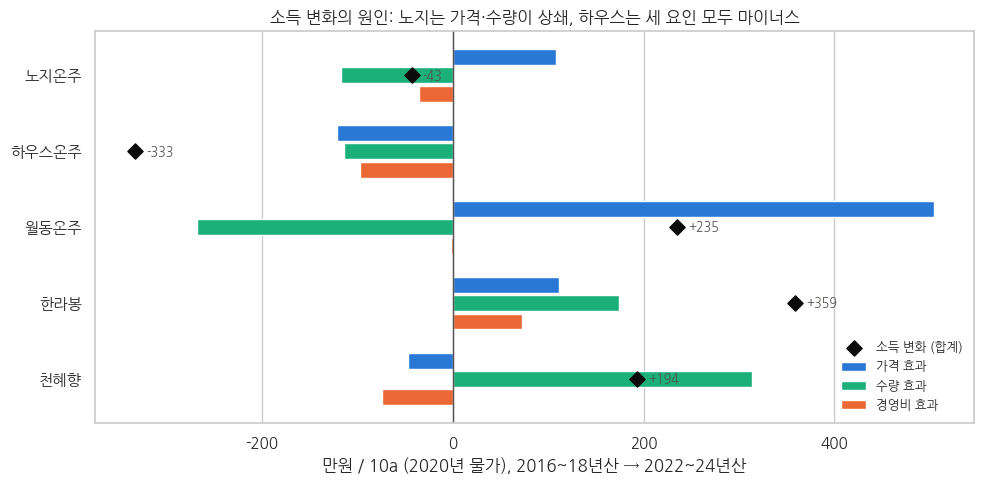

In [9]:
parts = ["가격 효과", "수량 효과", "경영비 효과"]
fig, ax = plt.subplots(figsize=(10, 5))
yy = np.arange(len(dec))
h = 0.24
for k, (part, color) in enumerate(zip(parts, [C1, C3, C2])):
    ax.barh(yy + (k - 1) * h, dec[part], height=h - 0.03, color=color, label=part)
ax.scatter(dec["소득 변화"], yy, marker="D", s=60, color="#0b0b0b", zorder=3, label="소득 변화 (합계)")
for yi, v in zip(yy, dec["소득 변화"]):
    ax.annotate(f"{v:+.0f}", (v, yi), xytext=(8, -3), textcoords="offset points", fontsize=9, color=MUTED)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(yy, dec.index)
ax.invert_yaxis()
ax.set_xlabel("만원 / 10a (2020년 물가), 2016~18년산 → 2022~24년산")
ax.set_title("소득 변화의 원인: 노지는 가격·수량이 상쇄, 하우스는 세 요인 모두 마이너스")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_income_decomposition.png", dpi=150)
plt.show()

In [10]:
g = t[t["대응품종"] == "노지온주"].set_index("산지연도")
print("노지온주 9년, 실질 소득과의 상관:",
      f"단가 {g['I'].corr(g['P']):+.2f} / 수량 {g['I'].corr(g['Y']):+.2f} / 경영비 {g['I'].corr(g['C']):+.2f}")
print(f"노지온주 표준 농가 단가와 수량의 상관: {g['P'].corr(g['Y']):+.2f}")

노지온주 9년, 실질 소득과의 상관: 단가 +0.44 / 수량 -0.05 / 경영비 -0.29
노지온주 표준 농가 단가와 수량의 상관: -0.88


**관찰**

- **노지온주**: 실질 단가는 31% 올랐지만(가격 효과 +108만원) 수량이 25% 줄어서(수량 효과 −116만원) 거의 상쇄됐습니다. 결국 **경영비 증가분(−35만원)만큼 소득이 줄었습니다**(−43만원/10a).
  표준 농가의 단가와 수량은 상관이 −0.88입니다. **값이 좋은 해는 수확이 적은 해**라서, 가격이 올라도 소득이 그만큼 늘지 않습니다.
- **하우스온주**: 가격(−121), 수량(−114), 경영비(−97)가 **모두 마이너스**입니다. 9년 동안 가장 크게 줄었습니다(−333만원/10a).
- **월동온주**: 단가가 55% 올라 수량 감소(−21%)를 이기고 +235만원 늘었습니다.
- **천혜향·한라봉**: 단가는 비슷하거나 조금 올랐고(천혜향 −3%, 한라봉 +9%), **수확량이 늘어서**(천혜향 +20%, 한라봉 +14%) 소득이 늘었습니다. 한라봉은 실질 경영비도 줄었습니다(+73만원 효과).

> 표준 농가 표본은 해마다 다를 수 있습니다. 수량 변화에는 실제 작황과 표본 구성 변화가 섞여 있습니다.

## 3. 표준표가 제주 평균보다 높은 이유: 수확량인가 단가인가?

`03` §1.3에서 만감류는 표준 농가의 총수입이 제주 평균의 1.1~3.7배였습니다. 이 비율은 정확히 세 부분의 곱으로 나뉩니다.

> 총수입 비 = **수량 비**(표준 수량 ÷ 제주 생산량/면적) × **단가 비**(표준 단가 ÷ 제주 조수입/생산량) × 부산물 보정

In [11]:
pj = prod.set_index(["품종", "연도"])
r = std[["산지연도", "대응품종", "수량_kg_10a", "단가_원_kg", "총수입_원_10a"]].copy()
key = list(zip(r["대응품종"], r["산지연도"]))
r["제주 수량_kg_10a"] = [pj.loc[k, "생산량_톤"] / pj.loc[k, "재배면적_ha"] * 100 for k in key]
r["제주 단가_원_kg"] = [pj.loc[k, "조수입_백만원"] * 1000 / pj.loc[k, "생산량_톤"] for k in key]
r["총수입 비"] = r["총수입_원_10a"] / [pj.loc[k, "ha당_조수입_백만원"] * 1e5 for k in key]
r["수량 비"] = r["수량_kg_10a"] / r["제주 수량_kg_10a"]
r["단가 비"] = r["단가_원_kg"] / r["제주 단가_원_kg"]
r["부산물 보정"] = r["총수입_원_10a"] / (r["수량_kg_10a"] * r["단가_원_kg"])
assert np.allclose(r["수량 비"] * r["단가 비"] * r["부산물 보정"], r["총수입 비"])
summary = r.groupby("대응품종")[["총수입 비", "수량 비", "단가 비"]].median().reindex(VARIETIES)
big_gap = summary["총수입 비"] >= 1.3  # 차이가 작으면 몫(%)이 불안정해서 계산하지 않음
summary["수량이 설명하는 몫 %"] = (np.log(summary["수량 비"]) / np.log(summary["총수입 비"]) * 100).where(big_gap)
print("9년(레드향 5년, 황금향 3년) 중앙값")
display(summary.style.format(precision=2, na_rep="-"))
print("수량 비 (연도별)")
r.pivot(index="대응품종", columns="산지연도", values="수량 비").reindex(VARIETIES).style.format(precision=2, na_rep="-")

9년(레드향 5년, 황금향 3년) 중앙값


,총수입 비,수량 비,단가 비,수량이 설명하는 몫 %
대응품종,,,,
노지온주,1.17,0.90,1.20,-
하우스온주,0.96,0.78,1.23,-
월동온주,1.17,1.12,1.05,-
한라봉,1.62,1.42,1.15,72.68
천혜향,1.79,1.69,1.16,89.61
레드향,1.73,1.49,1.15,72.46
황금향,2.36,1.12,1.83,13.33


수량 비 (연도별)


산지연도,2016,2017,2018,2019,2020,2021,2022,2023,2024
대응품종,,,,,,,,,
노지온주,1.15,1.04,0.89,1.03,0.84,0.97,0.83,0.90,0.66
하우스온주,0.78,0.71,0.77,0.72,0.75,0.78,0.93,0.90,0.84
월동온주,1.52,1.05,1.06,1.25,1.24,1.12,1.18,0.93,0.99
한라봉,0.97,1.29,1.17,1.47,1.42,1.59,1.48,1.60,1.27
천혜향,0.98,1.89,1.69,1.80,1.82,1.72,1.38,1.40,1.19
레드향,-,-,-,-,1.77,1.64,1.49,0.89,1.14
황금향,-,-,-,-,-,-,2.71,1.11,1.12


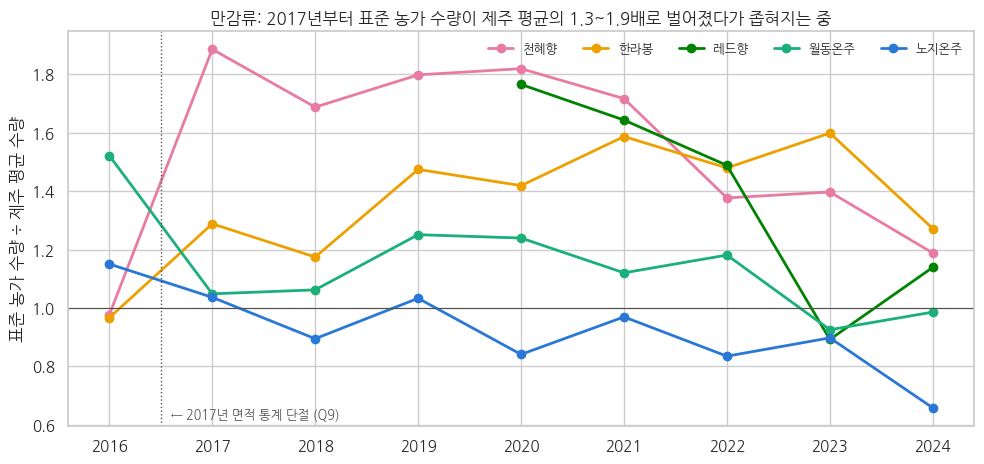

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for v in ["천혜향", "한라봉", "레드향", "월동온주", "노지온주"]:
    s = r[r["대응품종"] == v].set_index("산지연도")["수량 비"]
    ax.plot(s.index, s.values, color=VCOLOR[v], linewidth=2, marker="o", markersize=6, label=v)
ax.axvline(2016.5, color=MUTED, linewidth=1, linestyle=":")
ax.text(2016.6, 0.62, "← 2017년 면적 통계 단절 (Q9)", fontsize=9, color=MUTED)
ax.axhline(1, color=MUTED, linewidth=0.8)
ax.set_xticks(range(2016, 2025))
ax.set_ylabel("표준 농가 수량 ÷ 제주 평균 수량")
ax.set_title("만감류: 2017년부터 표준 농가 수량이 제주 평균의 1.3~1.9배로 벌어졌다가 좁혀지는 중")
ax.legend(loc="upper right", frameon=False, ncol=5, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_yield_gap_by_year.png", dpi=150)
plt.show()

**관찰**

- **만감류(천혜향·한라봉·레드향)의 차이는 대부분 수확량에서 나옵니다.** 천혜향은 수량 비 1.69배, 단가 비 1.16배로, 차이의 약 90%가 수량입니다. 표본 농가가 더 비싸게 파는 것이 아니라, **같은 면적에서 훨씬 많이 거둡니다.**
- **천혜향의 수량 비는 2016년 0.98배에서 2017년 1.89배로 뛰었습니다.** 2017년은 만감류 재배면적이 한 번에 2.5~4.4배로 늘어난 해입니다(`03` §2.2, Q9). 이후 1.19배까지 꾸준히 줄었습니다.
  이 흐름은 "2017년부터 **아직 수확하지 못하는 어린 과원이 재배면적에 포함**되었고, 나무가 자라면서 제주 평균 수량이 따라 올라왔다"는 설명과 맞습니다. 한라봉(0.97 → 1.29)도 같은 모양입니다.
- **노지온주·하우스온주는 반대로 단가 차이**입니다. 표본 농가 단가가 제주 평균보다 1.2배 높고, 수량은 오히려 적습니다(0.78~0.90배). 제주 평균 단가에는 값싼 가공용 물량이 섞여 있기 때문으로 보입니다.
- **황금향**은 단가 비가 1.83배입니다. 표준 농가의 수도광열비가 시설감귤에 가깝습니다(4절). 표본이 가온 시설 황금향이라 노지·비가림 위주의 제주 평균과 품목 자체가 다릅니다.

**의미**: 만감류의 제주 평균 ha당 매출은 수확 전 어린 과원 때문에 **실제 성과수 농가보다 낮게** 나옵니다. 반대로 표준표는 성과수 농가 기준이라 **신규 진입 농가의 기대 소득으로 쓰면 높게** 나옵니다. 품종 전환 상담에는 두 값을 함께 보여 줘야 합니다.

## 4. 품종별 경영비 물가지수

`03` §2.4의 노지 경영비지수를 7개 품종으로 넓혔습니다. 가중치는 2024년산 표준소득표의 경영비 세부 항목 15개를 농가구입가격지수 하위 지수 8개에 짝지어 계산했습니다.

In [13]:
wt = pd.DataFrame(weights).T.reindex(VARIETIES) * 100
print("경영비 구성 (%), 2024년산 표준소득표")
display(wt.round(0))
print("품종별 경영비지수 (2020=100)")
cost_idx.assign(CPI=cpi).loc[[2005, 2017, 2020, 2022, 2025], VARIETIES + ["CPI"]].round(1)

경영비 구성 (%), 2024년산 표준소득표


,비료비,농약비,영농자재비,노무비,영농광열비,임차료,경비,자산구입비
노지온주,9.0,22.0,6.0,27.0,3.0,6.0,3.0,23.0
하우스온주,4.0,7.0,1.0,10.0,43.0,0.0,1.0,33.0
월동온주,6.0,7.0,3.0,15.0,7.0,2.0,8.0,52.0
한라봉,10.0,8.0,7.0,19.0,13.0,1.0,4.0,38.0
천혜향,6.0,12.0,3.0,16.0,13.0,0.0,1.0,49.0
레드향,7.0,12.0,3.0,11.0,9.0,0.0,2.0,56.0
황금향,4.0,9.0,2.0,14.0,24.0,0.0,3.0,44.0


품종별 경영비지수 (2020=100)


,노지온주,하우스온주,월동온주,한라봉,천혜향,레드향,황금향,CPI
연도,,,,,,,,
2005,65.7,88.7,76.5,76.3,76.2,76.5,81.0,74.4
2017,90.4,99.5,94.6,94.9,94.7,94.7,96.5,97.6
2020,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2022,128.8,153.3,124.0,137.1,127.3,124.6,135.9,107.7
2025,132.5,140.9,124.4,132.1,127.0,124.1,131.7,116.6


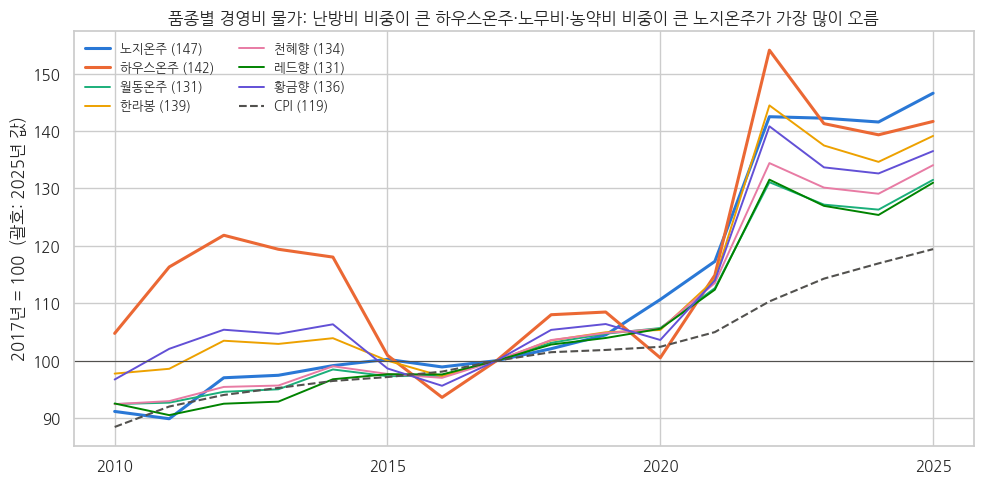

In [14]:
base = 2017
idx17 = (cost_idx[VARIETIES] / cost_idx.loc[base, VARIETIES] * 100).loc[2010:2025]
fig, ax = plt.subplots(figsize=(10, 5))
for v in VARIETIES:
    ax.plot(idx17.index, idx17[v], color=VCOLOR[v], linewidth=2.2 if v in ("하우스온주", "노지온주") else 1.4, label=f"{v} ({idx17.loc[2025, v]:.0f})")
cpi17 = (cpi / cpi[base] * 100).loc[2010:2025]
ax.plot(cpi17.index, cpi17.values, color=MUTED, linewidth=1.5, linestyle="--", label=f"CPI ({cpi17[2025]:.0f})")
ax.axhline(100, color=MUTED, linewidth=0.8)
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
ax.set_ylabel(f"{base}년 = 100  (괄호: 2025년 값)")
ax.set_title("품종별 경영비 물가: 난방비 비중이 큰 하우스온주·노무비·농약비 비중이 큰 노지온주가 가장 많이 오름")
ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_cost_index_by_variety.png", dpi=150)
plt.show()

In [15]:
out = []
for v in VARIETIES:
    g = prod[prod["품종"] == v].set_index("연도")
    row = {"품종": v}
    for name, dfl in [("CPI", cpi), ("경영비지수", cost_idx[v])]:
        rp = g["단가_원_kg"] / dfl
        rh = g["ha당_조수입_백만원"] / dfl
        row[f"단가 ({name})"] = (rp.loc[2023:2025].mean() / rp.loc[2017:2019].mean() - 1) * 100
        row[f"ha당 매출 ({name})"] = (rh.loc[2023:2025].mean() / rh.loc[2017:2019].mean() - 1) * 100
    out.append(row)
print("실질 변화율 %, 2017~19년 평균 → 2023~25년 평균 (Q9 면적 단절 이후 구간)")
pd.DataFrame(out).set_index("품종").round(1)

실질 변화율 %, 2017~19년 평균 → 2023~25년 평균 (Q9 면적 단절 이후 구간)


,단가 (CPI),ha당 매출 (CPI),단가 (경영비지수),ha당 매출 (경영비지수)
품종,,,,
노지온주,40.5,26.3,15.5,3.8
하우스온주,-6.4,-27.8,-19.2,-37.7
월동온주,42.1,11.8,31.5,3.4
한라봉,15.1,8.0,-0.2,-6.4
천혜향,0.1,66.4,-9.4,50.6
레드향,-1.3,59.9,-8.8,47.9
황금향,-2.7,124.0,-13.0,100.7


**관찰**

- 비용 구성이 품종마다 크게 다릅니다. **하우스온주는 난방(영농광열비)이 43%**, 노지온주는 **노무비 27%·농약비 22%**, 만감류는 **시설 상각(자산구입비)이 38~56%** 입니다.
- 그래서 2017년 이후 경영비 물가 상승도 다릅니다. **하우스온주 +42%, 노지온주 +47%** 로 가장 많이 올랐고, 만감류는 +31~39%입니다(CPI +19%).
- 비용 물가로 보정하면 **하우스온주의 ha당 실질 매출은 −38%** 로, CPI 기준(−28%)보다 더 나빠집니다. 표준표 실질 소득이 계속 줄어든 2절 결과와 같은 방향입니다.
- 천혜향·레드향·황금향은 비용 물가로 보정하면 **실질 단가가 −9 ~ −13%** 로 떨어졌지만, 수확량이 늘어서(3절) ha당 매출은 여전히 +48 ~ +101%입니다. **한라봉은 단가가 제자리(0%)이고 ha당 매출은 −6%** 입니다.
- 노지온주는 비용 기준 실질 단가가 +16%, ha당 매출이 +4%입니다. 3년 평균으로 비교하면 `03` §2.4의 연도 대 연도 비교(−5%)보다 조금 낫지만, **CPI 기준(+26%)보다 훨씬 작습니다.**

### 4절 한계

- 가중치는 2024년산 한 해의 비용 구성입니다. 노지온주는 2017년산 구성으로 바꿔도 결론 방향이 같았습니다(2017→2025 실질 단가 −4.9% → −9.2%, 손익분기 생산량 46.7 → 47.5만 톤).
- 만감류는 자산구입비 비중이 커서, **자산구입비 지수(2017년 이후 +10%)를 상각비 대신 쓴 근사**의 영향을 크게 받습니다. 상각비는 과거 시설 투자 가격을 나눠 반영하는 값이라 현재 가격 지수와 다르게 움직일 수 있습니다.

## 5. 요약

| 질문 | 답 | 확신도 |
| --- | --- | --- |
| 노지온주는 단가가 얼마면 적자인가? | 표준 농가 생산비 손익분기 단가는 885원(2016) → 2,229원(2024). 실제 단가와 거의 붙어 있고 2019·2022년산은 아래 | 높음 (표준표 기준) |
| 제주 평균 농가는? | 경영비 기준 9년 내내 흑자, **생산비 기준 2019~2022년산 4년 연속 적자** | 중간 (비용은 표준 농가로 가정) |
| 생산량이 몇 톤을 넘으면 위험한가? | 2026년산 기준 **약 47만 톤**(가격 변동을 감안하면 39~56만 톤) | 낮음~중간 (모델 예측력 제한) |
| 소득 변화의 원인은? | 노지: 가격↑·수량↓ 상쇄 후 비용 증가만 남음. 하우스: 가격·수량·비용 모두 악화. 천혜향·한라봉: 수확량 증가 | 중간 (표본 변화 포함) |
| 표준표가 왜 높은가? | 만감류는 **수확량 차이**(어린 과원이 면적에 포함), 노지·하우스는 **단가 차이**(가공용 포함) | 중간~높음 |
| 비용 물가로 보면? | 하우스 ha당 실질 매출 −38%, 노지 +4%, 한라봉 −6%. 천혜향·레드향·황금향은 단가 하락에도 수확량 증가로 매출 증가 | 중간 (가중치·상각비 근사) |